<div dir="rtl">

# تمرین اول مبانی بینایی کامپیوتر

## بخش اول: تحلیل و جداسازی رنگ‌ها در تصاویر دیجیتال

</div>

<div dir="rtl">

### ۱. بررسی مشخصات تصویر

</div>

<div dir="rtl">

تصویر با OpenCV بارگذاری می‌شود. ترتیب کانال‌های تصویر رنگی در خروجی `cv2.imread` برابر BGR (آبی، سبز، قرمز) است. محدودهٔ گزارش‌شده، کمترین و بیشترین مقدار واقعی میان همهٔ پیکسل‌ها و کانال‌هاست.

</div>

In [25]:
from pathlib import Path

import cv2
import matplotlib.pyplot as plt

image_path = Path("Media_src/Peppers.png")
image = cv2.imread(str(image_path), cv2.IMREAD_COLOR)

if image is None:
    raise FileNotFoundError(f"Could not load image: {image_path}")

In [26]:
height, width, channels = image.shape

print(f"Image dimensions (height x width): {height} x {width} pixels")
print(f"Array shape (height, width, channels): {image.shape}")
print(f"Data type: {image.dtype}")
print(f"Number of color channels: {channels}")
print("Channel order: BGR (Blue, Green, Red)")
print(f"Pixel value range: {image.min()} to {image.max()}")

Image dimensions (height x width): 1024 x 1536 pixels
Array shape (height, width, channels): (1024, 1536, 3)
Data type: uint8
Number of color channels: 3
Channel order: BGR (Blue, Green, Red)
Pixel value range: 0 to 255


<div dir="rtl">

برای نمایش درست رنگ‌ها با Matplotlib، تصویر BGR به RGB تبدیل می‌شود. این تبدیل فقط برای نمایش است و مشخصات بالا از تصویر بارگذاری‌شده محاسبه شده‌اند.

</div>

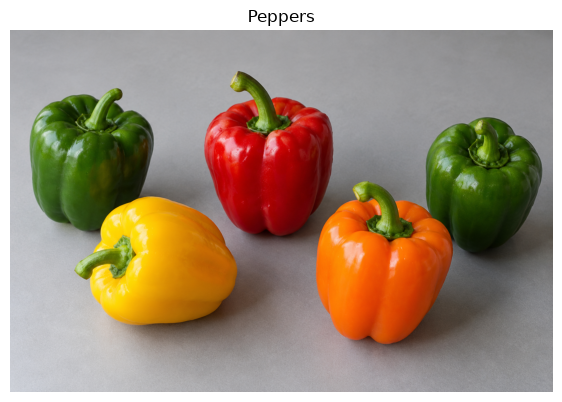

In [27]:
image_rgb = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)
plt.figure(figsize=(7, 5))
plt.imshow(image_rgb)
# plt.imshow(image)
plt.title("Peppers")
plt.axis("off")
plt.show()

<div dir="rtl">

### ۲. تبدیل انواع تصاویر

تصویر خاکستری با تبدیل استاندارد OpenCV ساخته می‌شود. برای تصویر 
دودویی، آستانهٔ ثابت ۱۲۷ انتخاب شده است؛ مقادیر بزرگ‌تر از آن سفید و بقیه سیاه می‌شوند.

 در تبدیل به خاکستری اطلاعات رنگ و در تبدیل به دودویی، علاوه بر رنگ، جزئیات سطوح روشنایی نیز از دست می‌روند.

</div>

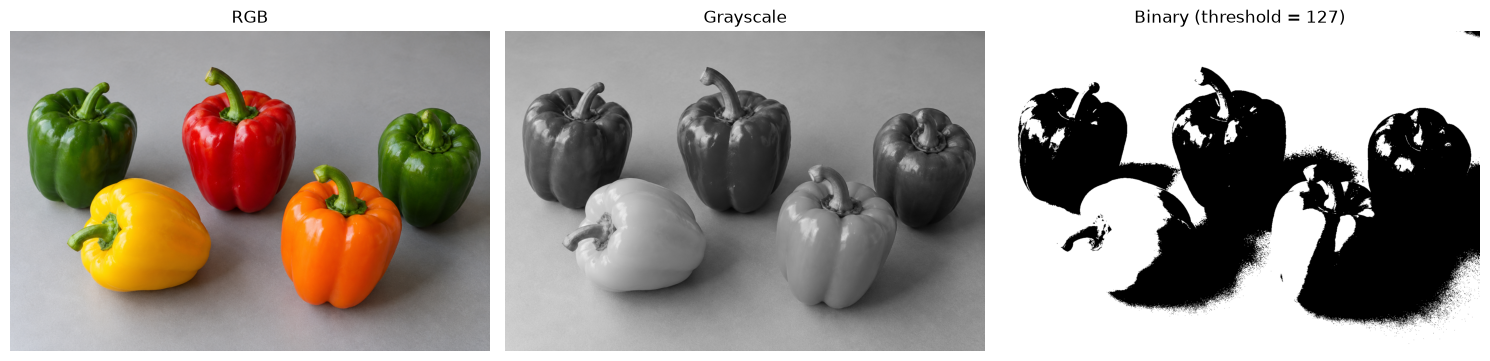

In [36]:
gray = cv2.cvtColor(image, cv2.COLOR_BGR2GRAY)
threshold = 127
_, binary = cv2.threshold(gray, threshold, 255, cv2.THRESH_BINARY)

fig, axes = plt.subplots(1, 3, figsize=(15, 5))
for ax, picture, title in zip(axes, [image_rgb, gray, binary], ["RGB", "Grayscale", "Binary (threshold = 127)"]):
    ax.imshow(picture, cmap="gray" if picture.ndim == 2 else None, vmin=0, vmax=255)
    # ax.imshow(picture, vmin=0, vmax=255)
    ax.set_title(title)
    ax.axis("off")
plt.tight_layout()
plt.show()

<div dir="rtl">

### ۳. بررسی فضاهای رنگی RGB و HSV

در RGB هر کانال سهم یک رنگ اصلی را نشان می‌دهد. در HSV، مؤلفه‌های رنگ‌فام (H)، اشباع (S) و روشنایی (V) جدا شده‌اند؛ بنابراین با وجود حساسیت به نور و اشباع کم، HSV برای تعیین بازهٔ رنگی اجسام مناسب‌تر است. در OpenCV برای تصویر ۸ بیتی، H در بازهٔ ۰ تا ۱۷۹ و دو کانال دیگر در بازهٔ ۰ تا ۲۵۵ قرار دارند.

</div>

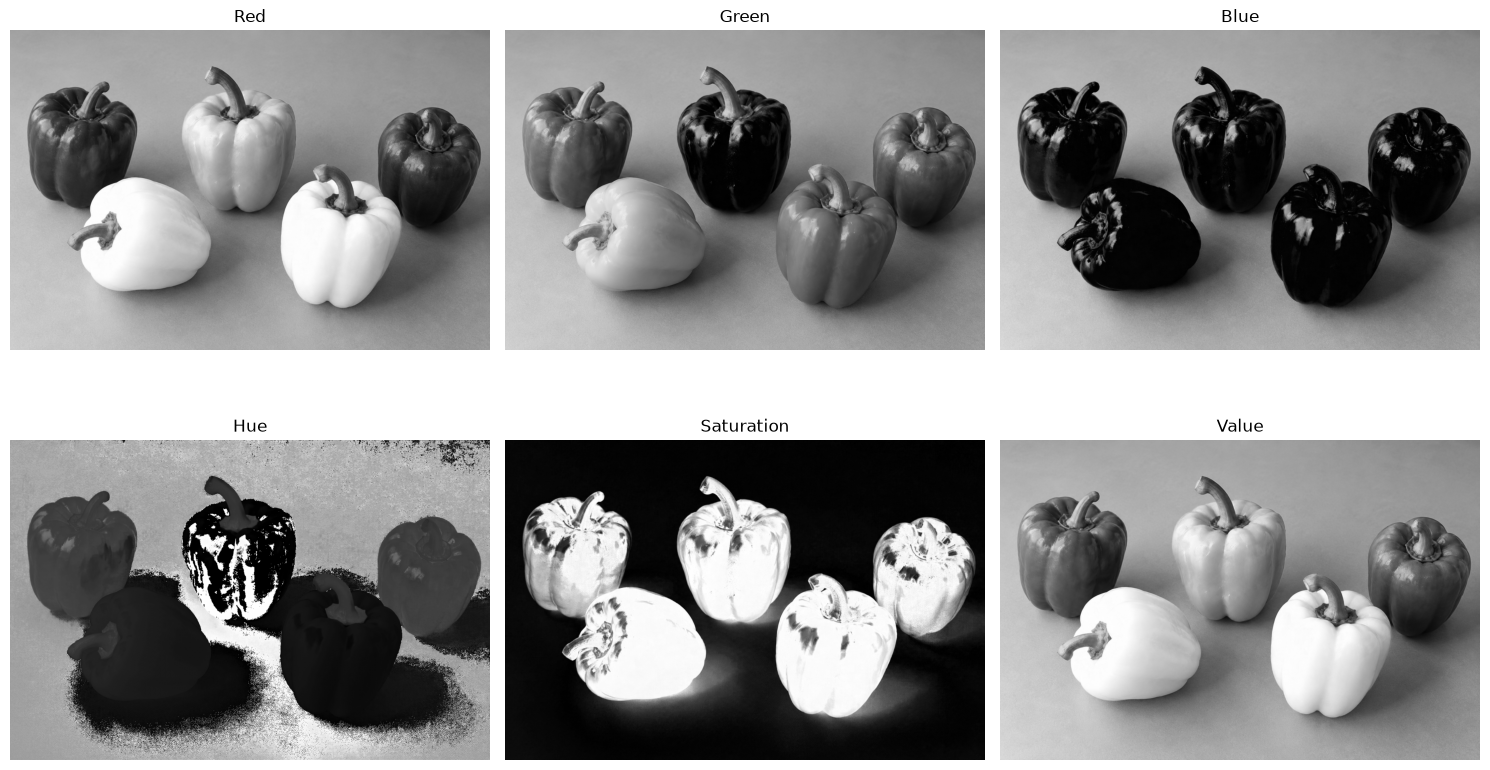

In [29]:
hsv = cv2.cvtColor(image, cv2.COLOR_BGR2HSV)
fig, axes = plt.subplots(2, 3, figsize=(15, 9))
for row, (color_image, names) in enumerate([(image_rgb, ["Red", "Green", "Blue"]), (hsv, ["Hue", "Saturation", "Value"])]):
    for index, name in enumerate(names):
        axes[row, index].imshow(color_image[:, :, index], cmap="gray", vmin=0, vmax=179 if name == "Hue" else 255)
        axes[row, index].set_title(name)
        axes[row, index].axis("off")
plt.tight_layout()
plt.show()

<div dir="rtl">

### ۴. جداسازی نواحی سبز

برای شناسایی رنگ سبز از بازهٔ HSV با حدود `[35, 50, 40]` تا `[85, 255, 255]` استفاده می‌شود. حداقل اشباع و روشنایی برای کاهش انتخاب نواحی خاکستری و بسیار تاریک است. این روش فقط بر اساس رنگ تصمیم می‌گیرد؛ بنابراین ممکن است برگ، ساقه یا پس‌زمینهٔ سبز نیز انتخاب شوند و تضمین نمی‌کند همهٔ پیکسل‌های ماسک متعلق به فلفل باشند.

در خروجی این تصویر علاوه بر بدنهٔ فلفل‌های سبز، ساقه‌های سبز فلفل‌های قرمز، زرد و نارنجی نیز انتخاب شده‌اند. همچنین بخش‌هایی از فلفل‌های سبز در نواحی تیره یا بازتاب نور از ماسک جا مانده‌اند.

</div>

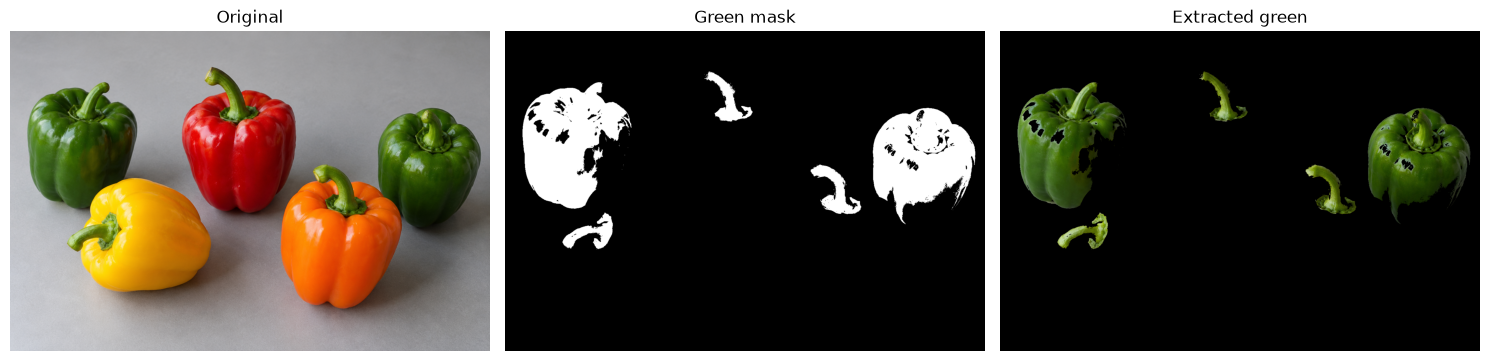

Green mask coverage: 11.59%


In [30]:
import numpy as np

green_lower = np.array([35, 50, 40], dtype=np.uint8)
green_upper = np.array([85, 255, 255], dtype=np.uint8)

def extract_green(bgr_image):
    hsv_image = cv2.cvtColor(bgr_image, cv2.COLOR_BGR2HSV)
    mask = cv2.inRange(hsv_image, green_lower, green_upper)
    result = cv2.bitwise_and(bgr_image, bgr_image, mask=mask)
    return mask, result

green_mask, green_image = extract_green(image)
fig, axes = plt.subplots(1, 3, figsize=(15, 5))
for ax, picture, title in zip(axes, [image_rgb, green_mask, cv2.cvtColor(green_image, cv2.COLOR_BGR2RGB)], ["Original", "Green mask", "Extracted green"]):
    ax.imshow(picture, cmap="gray" if picture.ndim == 2 else None, vmin=0, vmax=255)
    ax.set_title(title)
    ax.axis("off")
plt.tight_layout()
plt.show()
print(f"Green mask coverage: {np.mean(green_mask > 0) * 100:.2f}%")

<div dir="rtl">

### ۵. هیستوگرام و کنتراست

کنتراست RMS، انحراف معیار شدت پیکسل‌های تصویر خاکستری است. در اینجا شدت‌ها بر ۲۵۵ تقسیم می‌شوند، پس مقدار کنتراست بدون واحد و در مقیاس صفر تا یک است. برای تغییر کنتراست، فاصلهٔ هر پیکسل از میانگین تصویر در یک ضریب ضرب و مقادیر به بازهٔ مجاز محدود می‌شوند. ضریب ۱٫۵ کنتراست را افزایش و ضریب ۰٫۵ آن را کاهش می‌دهد؛ برش در دو انتهای بازه می‌تواند بخشی از جزئیات را از بین ببرد.

</div>

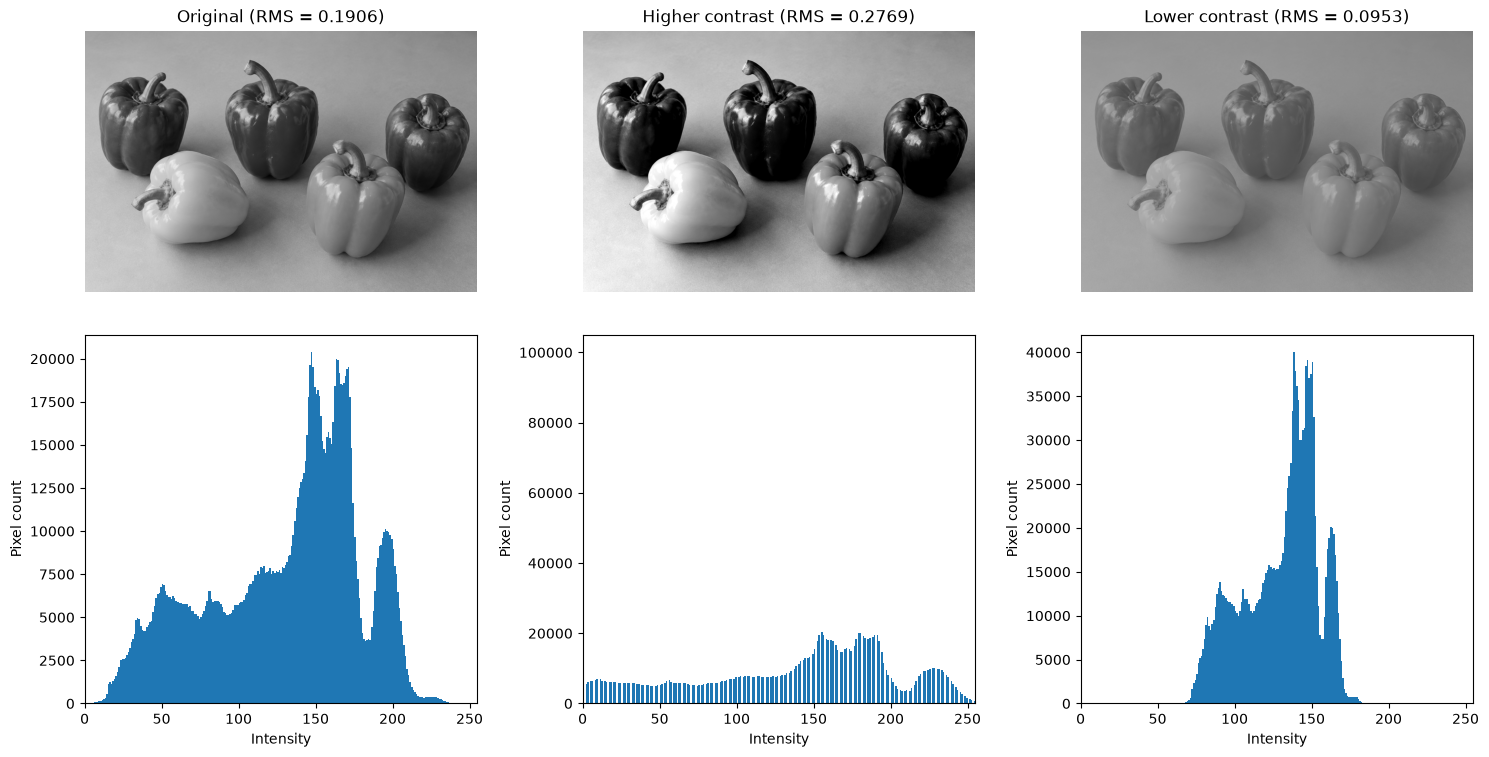

Original: RMS = 0.1906
Higher contrast: RMS = 0.2769
Lower contrast: RMS = 0.0953
Original grayscale: min = 0, max = 251, mean = 130.29


In [31]:
def rms_contrast(gray_image):
    return np.std(gray_image.astype(np.float64) / 255.0)

def change_contrast(gray_image, factor):
    mean = gray_image.mean()
    adjusted = (gray_image.astype(np.float64) - mean) * factor + mean
    return np.clip(adjusted, 0, 255).astype(np.uint8)

contrast_images = [gray, change_contrast(gray, 1.5), change_contrast(gray, 0.5)]
contrast_names = ["Original", "Higher contrast", "Lower contrast"]
fig, axes = plt.subplots(2, 3, figsize=(15, 8))
for index, (picture, name) in enumerate(zip(contrast_images, contrast_names)):
    axes[0, index].imshow(picture, cmap="gray", vmin=0, vmax=255)
    axes[0, index].set_title(f"{name} (RMS = {rms_contrast(picture):.4f})")
    axes[0, index].axis("off")
    axes[1, index].hist(picture.ravel(), bins=256, range=(0, 256))
    axes[1, index].set_xlim(0, 255)
    axes[1, index].set_xlabel("Intensity")
    axes[1, index].set_ylabel("Pixel count")
plt.tight_layout()
plt.show()
for name, picture in zip(contrast_names, contrast_images):
    print(f"{name}: RMS = {rms_contrast(picture):.4f}")
print(f"Original grayscale: min = {gray.min()}, max = {gray.max()}, mean = {gray.mean():.2f}")

<div dir="rtl">

هیستوگرام بالا توزیع واقعی روشنایی تصویر را نشان می‌دهد. در نسخهٔ پرکنتراست، مقادیر از میانگین دورتر می‌شوند و ممکن است در صفر و ۲۵۵ انباشته شوند؛ در نسخهٔ کم‌کنتراست توزیع به میانگین نزدیک‌تر می‌شود. مقادیر عددی چاپ‌شده میزان تغییر را مشخص می‌کنند.

در تصویر خاکستری اصلی، سهم بازه‌های ۰–۶۳، ۶۴–۱۲۷، ۱۲۸–۱۹۱ و ۱۹۲–۲۵۵ به‌ترتیب 13.9، 25.6، 51.4 و 9.1 درصد است. میانگین شدت حدود ۱۳۰ است.

</div>

<div dir="rtl">

### ۶. بهبود تصویر در نور نامناسب

برای شبیه‌سازی نور ضعیف، کانال روشنایی V در فضای HSV در ۰٫۳ ضرب می‌شود. برای حفظ تقریبی رنگ‌فام و اشباع، همسان‌سازی هیستوگرام و کشش خطی تنها روی کانال V تصویر تاریک اعمال می‌شوند و سپس تصویر به BGR برمی‌گردد. کشش، کمینه و بیشینهٔ موجود در کانال V را به ۰ و ۲۵۵ می‌نگارد. همسان‌سازی به توزیع مقادیر وابسته است، اما کشش، فاصله‌های نسبی شدت را به‌صورت خطی حفظ می‌کند؛ تبدیل و گرد کردن می‌توانند باعث تغییر جزئی رنگ شوند.

</div>

Dark: V range = 0 to 76, mean = 45.50
Histogram equalization: V range = 0 to 255, mean = 130.49
Histogram stretching: V range = 0 to 255, mean = 152.15


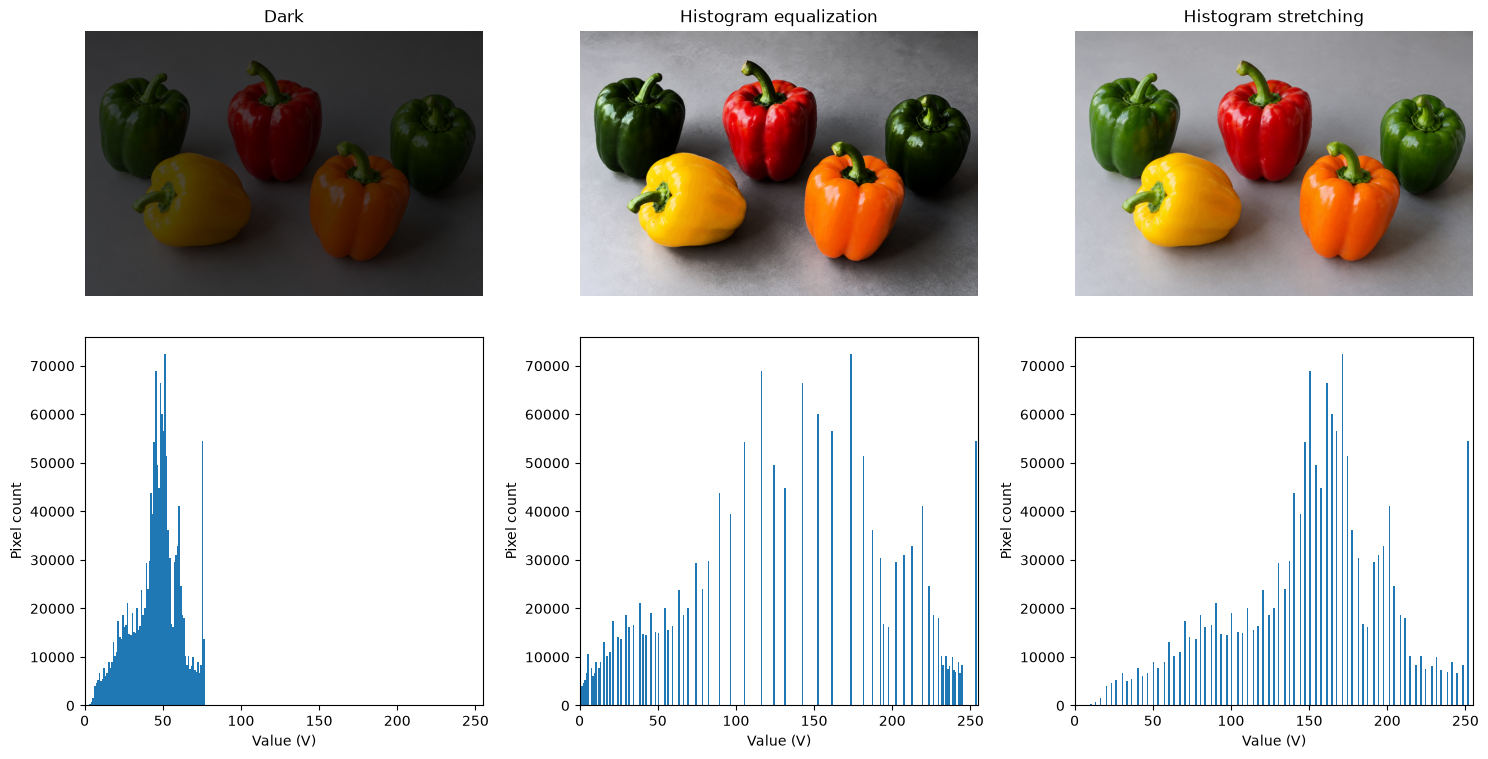

In [32]:
dark_hsv = hsv.copy()
dark_hsv[:, :, 2] = (hsv[:, :, 2].astype(np.float32) * 0.3).astype(np.uint8)
dark_image = cv2.cvtColor(dark_hsv, cv2.COLOR_HSV2BGR)

# Start from the same dark image for both enhancement methods.
dark_hsv = cv2.cvtColor(dark_image, cv2.COLOR_BGR2HSV)
dark_value = dark_hsv[:, :, 2]
equalized_hsv = dark_hsv.copy()
equalized_hsv[:, :, 2] = cv2.equalizeHist(dark_value)
equalized_image = cv2.cvtColor(equalized_hsv, cv2.COLOR_HSV2BGR)

stretched_hsv = dark_hsv.copy()
value_min, value_max = int(dark_value.min()), int(dark_value.max())
if value_max > value_min:
    stretched = (dark_value.astype(np.float32) - value_min) * 255 / (value_max - value_min)
    stretched_hsv[:, :, 2] = np.clip(stretched, 0, 255).astype(np.uint8)
stretched_image = cv2.cvtColor(stretched_hsv, cv2.COLOR_HSV2BGR)

enhanced_images = [dark_image, equalized_image, stretched_image]
enhanced_names = ["Dark", "Histogram equalization", "Histogram stretching"]
fig, axes = plt.subplots(2, 3, figsize=(15, 8))
for index, (picture, name) in enumerate(zip(enhanced_images, enhanced_names)):
    axes[0, index].imshow(cv2.cvtColor(picture, cv2.COLOR_BGR2RGB))
    axes[0, index].set_title(name)
    axes[0, index].axis("off")
    value = cv2.cvtColor(picture, cv2.COLOR_BGR2HSV)[:, :, 2]
    axes[1, index].hist(value.ravel(), bins=256, range=(0, 256))
    axes[1, index].set_xlim(0, 255)
    axes[1, index].set_xlabel("Value (V)")
    axes[1, index].set_ylabel("Pixel count")
    print(f"{name}: V range = {value.min()} to {value.max()}, mean = {value.mean():.2f}")
plt.tight_layout()
plt.show()

<div dir="rtl">

در نمودارها هیستوگرام کانال V، همان کانال پردازش‌شده، نمایش داده شده است. همسان‌سازی می‌تواند توزیع روشنایی را به شکل غیرخطی تغییر دهد و جزئیات بعضی بازه‌ها را تقویت کند؛ کشش با تبدیل خطی دامنه را گسترش می‌دهد و به کمینه و بیشینه حساس است. هیچ‌یک تضمین نمی‌کند روشنایی اصلی دقیقاً بازیابی شود.

</div>

<div dir="rtl">

### ۷. تأثیر بهبود تصویر بر جداسازی رنگ

همان تابع و حدود HSV قسمت ۴، بدون تغییر، برای تصویر اصلی، تاریک و دو تصویر بهبودیافته استفاده می‌شوند. نسبت پیکسل‌های انتخاب‌شده و اشتراک بر اجتماع (IoU) هر ماسک با ماسک اصلی گزارش می‌شوند. ماسک اصلی مرجع مقایسه است، نه دادهٔ حقیقت مبنا؛ در نتیجه IoU میزان شباهت به خروجی اولیه را نشان می‌دهد و معیار دقت واقعی تشخیص فلفل نیست.

</div>

Original: coverage = 11.59%, IoU with original = 1.000
Dark: coverage = 1.98%, IoU with original = 0.164
Equalized: coverage = 5.02%, IoU with original = 0.421
Stretched: coverage = 11.82%, IoU with original = 0.981


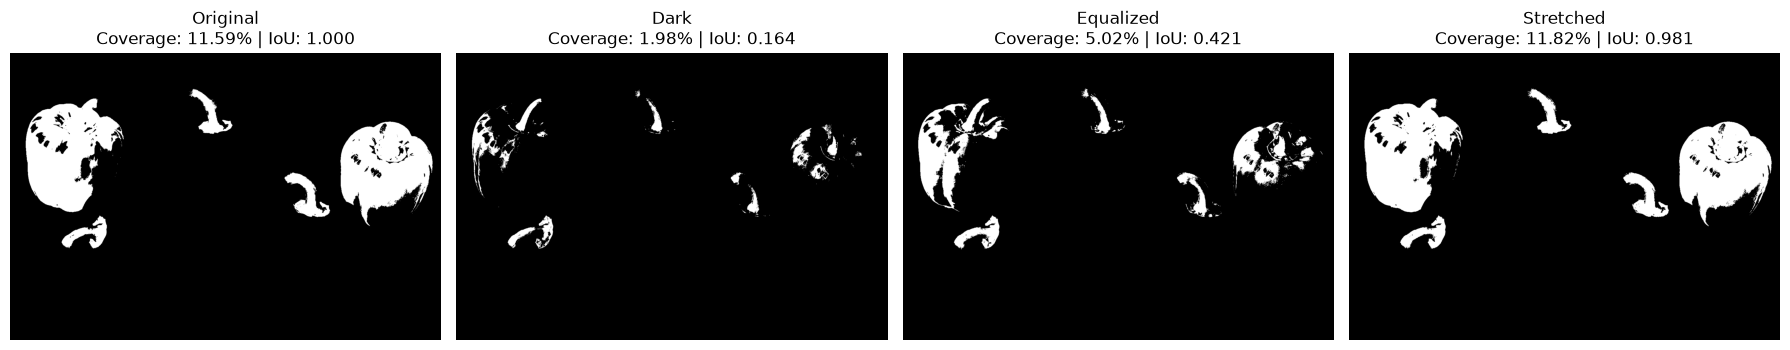

In [33]:
comparison_images = [image, dark_image, equalized_image, stretched_image]
comparison_names = ["Original", "Dark", "Equalized", "Stretched"]
comparison_masks = [extract_green(picture)[0] for picture in comparison_images]
reference = green_mask > 0

fig, axes = plt.subplots(1, 4, figsize=(18, 5))
for ax, mask, name in zip(axes, comparison_masks, comparison_names):
    selected = mask > 0
    union = np.logical_or(reference, selected).sum()
    iou = np.logical_and(reference, selected).sum() / union if union else 1.0
    coverage = selected.mean() * 100
    ax.imshow(mask, cmap="gray", vmin=0, vmax=255)
    ax.set_title(f"{name}\nCoverage: {coverage:.2f}% | IoU: {iou:.3f}")
    ax.axis("off")
    print(f"{name}: coverage = {coverage:.2f}%, IoU with original = {iou:.3f}")
plt.tight_layout()
plt.show()

<div dir="rtl">

تاریک‌سازی می‌تواند پیکسل‌ها را به زیر حداقل روشنایی تعیین‌شده ببرد و از ماسک حذف کند. بهبود روشنایی ممکن است بخشی از آن‌ها را بازگرداند یا پیکسل‌های تازه‌ای را وارد ماسک کند. مقایسهٔ درصد پوشش و IoU در خروجی بالا نشان می‌دهد هر روش برای این تصویر چقدر ماسک را نسبت به حالت اصلی تغییر داده است؛ شباهت بیشتر به ماسک اصلی لزوماً به معنی تشخیص درست‌تر فلفل نیست.

برای این تصویر، پوشش ماسک از ۱۱٫۵۹٪ در حالت اصلی به ۱٫۹۸٪ در حالت تاریک می‌رسد. پس از همسان‌سازی و کشش به‌ترتیب ۵٫۰۲٪ و ۱۱٫۸۲٪ است. IoU این سه حالت با ماسک اصلی به‌ترتیب ۰٫۱۶۴، ۰٫۴۲۱ و ۰٫۹۸۱ است؛ در این آزمایش کشش بیشترین شباهت را به ماسک اولیه دارد.

</div>